# PMF on PCA — Reference Formula
## Using -0.002 * 300 * log10(H) — same as reference script

In [17]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch

base       = "/home/computer2/analysis_simulations/analysis/pca_combined/"
output_dir = "/home/computer2/analysis_simulations/analysis/pmf_plots_ref"
os.makedirs(output_dir, exist_ok=True)

# Same colormap as reference
custom_cmap = matplotlib.colors.LinearSegmentedColormap.from_list(
    'custom', ['red', 'yellow', 'green', 'white'])

CLR_GLY = '#2E86AB'
CLR_NOG = '#A23B72'

print('Ready. Output:', output_dir)

Ready. Output: /home/computer2/analysis_simulations/analysis/pmf_plots_ref


In [18]:
def load_dat(filepath):
    d   = np.genfromtxt(filepath, comments='#', dtype=None,
                        encoding='utf-8', names=['pc1', 'pc2', 'system'])
    pc1 = d['pc1'].astype(float)
    pc2 = d['pc2'].astype(float)
    sys = np.array([s.strip() for s in d['system']])
    return pc1, pc2, sys


def make_pmf_figure(dat_file, title, outpath):
    """
    Reference formula: H_prob = -0.002 * 300 * log10(H)
    Zeros replaced with 1 (so log10(1) = 0).
    Shared bins and shared colour scale across both systems.
    Two panels side by side — one per system.
    """
    pc1, pc2, labels = load_dat(dat_file)
    gly = labels == 'glycans'
    nog = labels == 'noglycans'
    print(f'  {gly.sum()} glycans  |  {nog.sum()} noglycans')

    xmin = min(pc1[gly].min(), pc1[nog].min())
    xmax = max(pc1[gly].max(), pc1[nog].max())
    ymin = min(pc2[gly].min(), pc2[nog].min())
    ymax = max(pc2[gly].max(), pc2[nog].max())

    bins_x = np.linspace(xmin, xmax, 50)
    bins_y = np.linspace(ymin, ymax, 50)

    H1, xedges, yedges = np.histogram2d(pc1[gly], pc2[gly], bins=(bins_x, bins_y))
    H2, _,      _      = np.histogram2d(pc1[nog], pc2[nog], bins=(bins_x, bins_y))

    H1 = np.where(H1 == 0, 1, H1)
    H2 = np.where(H2 == 0, 1, H2)

    H_prob1 = -0.002 * 300 * np.log10(H1)
    H_prob2 = -0.002 * 300 * np.log10(H2)

    vmin = min(H_prob1.min(), H_prob2.min())
    vmax = -0.1

    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])

    fig = plt.figure(figsize=(14, 5.5), dpi=100)
    fig.set_facecolor('white')
    ax1 = fig.add_axes([0.07, 0.13, 0.40, 0.77])
    ax2 = fig.add_axes([0.53, 0.13, 0.40, 0.77])
    cax = fig.add_axes([0.95, 0.13, 0.018, 0.77])

    img1 = ax1.contourf(xc, yc, H_prob1.T, cmap=custom_cmap,
                        vmin=vmin, vmax=vmax,
                        levels=np.linspace(vmin, vmax, 25))
    img2 = ax2.contourf(xc, yc, H_prob2.T, cmap=custom_cmap,
                        vmin=vmin, vmax=vmax,
                        levels=np.linspace(vmin, vmax, 25))

    cbar = fig.colorbar(img1, cax=cax)
    cbar.set_label('logP', fontsize=13, fontname='DejaVu Serif',
                   fontweight='bold', labelpad=10)
    cbar.ax.tick_params(labelsize=11)

    ax1.set_title('Glycosylated', fontsize=20,
                  fontname='DejaVu Serif', fontweight='bold', pad=10)
    ax2.set_title('Non-glycosylated', fontsize=20,
                  fontname='DejaVu Serif', fontweight='bold', pad=10)

    for ax in (ax1, ax2):
        ax.set_xlabel('PC1', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
        ax.set_ylabel('PC2', fontsize=14, fontname='DejaVu Serif', fontweight='bold')
        ax.set_facecolor('white')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(True)
        ax.spines['left'].set_color('black')
        ax.spines['left'].set_linewidth(1.5)
        ax.spines['bottom'].set_visible(True)
        ax.spines['bottom'].set_color('black')
        ax.spines['bottom'].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=12,
                       length=6, width=1.5, direction='out', colors='black')
        ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
        ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

    fig.suptitle(title, fontsize=14,
                 fontname='DejaVu Serif', fontweight='bold', y=1.02)
    plt.savefig(outpath, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'  Saved: {outpath}')


print('Functions loaded.')

Functions loaded.


## Figure 1 — Long PTS with End Terminals Attached

  2505 glycans  |  2381 noglycans


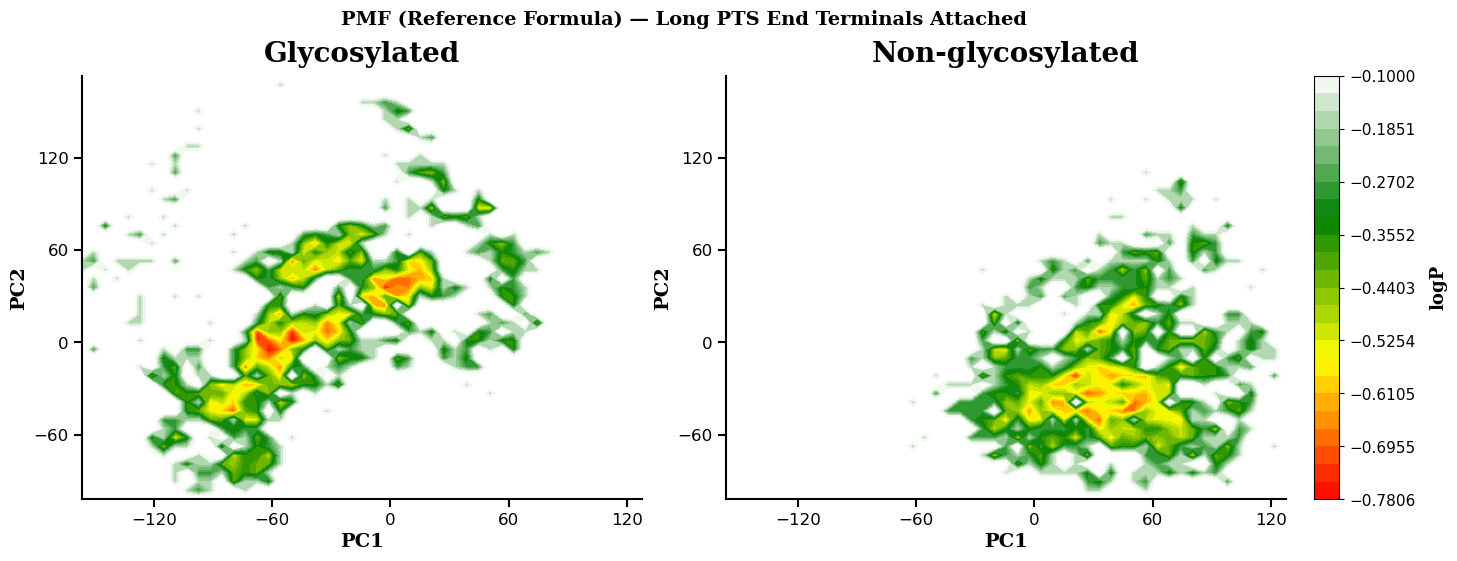

  Saved: /home/computer2/analysis_simulations/analysis/pmf_plots_ref/pmf_ref_fullstruct.png


In [19]:
make_pmf_figure(
    dat_file = base + 'longpts_from_fullstruct_pca.dat',
    title    = 'PMF (Reference Formula) — Long PTS End Terminals Attached',
    outpath  = os.path.join(output_dir, 'pmf_ref_fullstruct.png')
)

## Figure 2 — Long PTS Section Cut

  2505 glycans  |  2381 noglycans


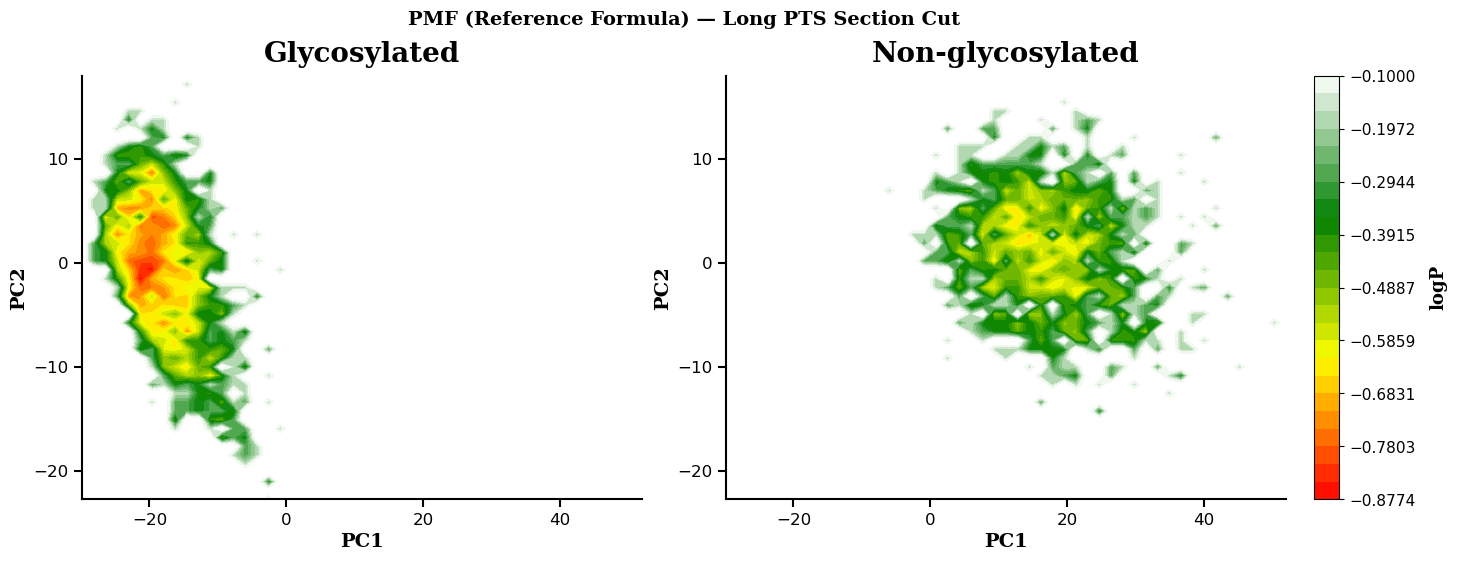

  Saved: /home/computer2/analysis_simulations/analysis/pmf_plots_ref/pmf_ref_sectiononly.png


In [20]:
make_pmf_figure(
    dat_file = base + 'pca_coords_justlongpts.dat',
    title    = 'PMF (Reference Formula) — Long PTS Section Cut',
    outpath  = os.path.join(output_dir, 'pmf_ref_sectiononly.png')
)